# aci_tallies quickstart

`aci_tallies` reads MCNP tally files into NumPy arrays, however large they
are. This notebook uses the bundled example: [`simple_model.mcnp`](simple_model.mcnp)
defines nine FMESH tallies covering MCNP's geometry, `out=`, energy and time
options, and [`meshtal`](meshtal) is its (real, MCNP-written) output.

## Opening a file reads where everything is, not the values

`aci_tallies.open` indexes the file in one parallel pass and reads each
tally's header. Values are read when asked for, a tally or a bin at a time,
so a 50 GB file opens in a fraction of a second and only what you use is
ever in memory. In a notebook the file shows as a table of its tallies.

In [1]:
import aci_tallies
import numpy as np

f = aci_tallies.open("meshtal")
f

tally,particle,mesh,energy bins,time bins,out,comment,warnings
14,neutron,rectangular: x=5 × y=5 × z=5,—,—,col,,
24,neutron,rectangular: x=5 × y=6 × z=7,—,—,col,Simple FMESH,
34,neutron,rectangular: x=5 × y=5 × z=5,10 + Total (0 – 1e-05 MeV),—,col,Energy discretization,
44,neutron,rectangular: x=5 × y=5 × z=5,—,—,ij,IJ Format,
54,neutron,rectangular: x=5 × y=5 × z=5,—,—,ik,IK Format,
64,neutron,rectangular: x=5 × y=5 × z=5,—,—,cf,CF Format,
74,neutron,cylindrical: r=10 × z=10 × theta=10,—,—,col,Cylindrical coordinates,
84,neutron,rectangular: x=5 × y=5 × z=5,—,3 + Total (-1e+36 – 5e+08 sh),col,Time discretization,
94,neutron,rectangular: x=5 × y=5 × z=5,10 + Total (0 – 1e-05 MeV),3 + Total (-1e+36 – 5e+08 sh),col,Energy and Time discretization,


A file works like a dictionary from tally number to tally: `f.ids`,
`14 in f`, `f[14]`. `f.tallies` describes each without reading any values,
and `f.failed` lists sections that couldn't be read (a damaged section
never stops the rest of the file from being read).

In [2]:
print(f.ids, f.failed)
for info in f.tallies:
    print(f"tally {info.id:>3}  {info.geometry.kind:<11} shape={info.shape}  out={info.out_format:<3}  comment={info.comment!r}")

[14, 24, 34, 44, 54, 64, 74, 84, 94] []
tally  14  rectangular shape=[1, 1, 5, 5, 5]  out=col  comment=None
tally  24  rectangular shape=[1, 1, 5, 6, 7]  out=col  comment='Simple FMESH'
tally  34  rectangular shape=[11, 1, 5, 5, 5]  out=col  comment='Energy discretization'
tally  44  rectangular shape=[1, 1, 5, 5, 5]  out=ij   comment='IJ Format'
tally  54  rectangular shape=[1, 1, 5, 5, 5]  out=ik   comment='IK Format'
tally  64  rectangular shape=[1, 1, 5, 5, 5]  out=cf   comment='CF Format'
tally  74  cylindrical shape=[1, 1, 10, 10, 10]  out=col  comment='Cylindrical coordinates'
tally  84  rectangular shape=[1, 4, 5, 5, 5]  out=col  comment='Time discretization'
tally  94  rectangular shape=[11, 4, 5, 5, 5]  out=col  comment='Energy and Time discretization'


## NumPy access

`result` and `rel_error` always have five axes, `(energy, time, i, j, k)`:
a mesh without `EMESH`/`TMESH` still has length 1 there. They are read-only
views of what Rust read (no copy); `np.array(t.result)` gives a writable
copy. The mesh is `t.geometry`.

In [3]:
t14 = f[14]
print(t14.result.shape, t14.result.dtype, "writeable:", t14.result.flags.writeable)
print(t14.geometry, t14.geometry.axis_names)
print("x bounds    :", t14.geometry.bounds[0])
print("centre voxel:", t14.result[0, 0, 2, 2, 2], "+/-", t14.rel_error[0, 0, 2, 2, 2])

(1, 1, 5, 5, 5) float64 writeable: False
Geometry(rectangular, x=5, y=5, z=5) ('x', 'y', 'z')
x bounds    : [-10.  -6.  -2.   2.   6.  10.]
centre voxel: 0.0382462 +/- 0.000135894


In [4]:
t14

particle,neutron
comment,
mesh,rectangular: x=5 × y=5 × z=5
energy bins,—
time bins,—
shape,"(1, 1, 5, 5, 5)"
out,col
result,"min 0.0002291, max 0.03825"
rel. error,max 0.01555 where scored; 125 of 125 values scored


## Every `out=` layout reads the same

Tallies 44 (`out=ij`) and 54 (`out=ik`) are the same run as tally 14
(`out=col`), printed as matrices instead of columns: their arrays agree.

In [5]:
t44, t54 = f[44], f[54]
print("ij matches col:", np.allclose(t14.result, t44.result, rtol=1e-6))
print("ik matches col:", np.allclose(t14.result, t54.result, rtol=1e-6))
# The matrix layouts print relative errors with fewer digits.
print("ij rel_error  :", np.allclose(t14.rel_error, t44.rel_error, atol=1e-5))

ij matches col: True
ik matches col: True
ij rel_error  : True


## Energy bins and MCNP's Total bin

Tally 34 has 10 energy bins. When an axis has more than one bin MCNP also
prints a Total bin; it is one more index at the end of the axis
(`t.energy.total`, `t.energy.total_index`), never dropped.
`integrate_energy()` returns it rather than summing the bins: MCNP derives
its error from the histories, which a quadrature sum can't reproduce.

In [6]:
t34 = f[34]
print(t34.energy)
print("shape:", t34.result.shape)
print("centre voxel per bin:", t34.result[: t34.energy.n_bins, 0, 2, 2, 2])
print("centre voxel Total  :", t34.result[t34.energy.total_index, 0, 2, 2, 2])
integrated = t34.integrate_energy()
print("integrated:", integrated.result.shape, integrated.energy)

Axis(bounds=[0.0, 1e-6, ..., 1e-5] (10 bins), total=True)
shape: (11, 1, 5, 5, 5)
centre voxel per bin: [4.65411e+12 1.47798e+11 8.44130e+10 2.56601e+10 6.21207e+10 3.78195e+10
 1.88454e+10 3.61592e+10 1.12587e+10 2.80782e+10]
centre voxel Total  : 5106260000000.0
integrated: (1, 1, 5, 5, 5) Axis(bounds=[0.0, 1e-5], total=False)


## Reading only some bins

`f.read(id, energy=..., time=...)` reads only those bins' part of the file
(an index, or `"total"`); the result still has five axes. On a large file
this is the way to look at one energy bin without reading the others.

In [7]:
total = f.read(34, energy="total")
print(total.result.shape, total.energy)
print(np.array_equal(total.result[0], t34.result[-1]))

(1, 1, 5, 5, 5) Axis(bounds=[0.0, 1e-5], total=False)
True


## Time bins

Tally 84 has `TMESH` time bins and tally 94 both energy and time bins, so
MCNP prints every combination of Totals; all are plain indices.

In [8]:
t84, t94 = f[84], f[94]
print(t84.time, t84.result.shape)
print(t94.result.shape)
grand_total = t94.result[t94.energy.total_index, t94.time.total_index]
print("Total/Total, corner voxel:", grand_total[0, 0, 0])

Axis(bounds=[-1e36, 100000000.0, 200000000.0, 500000000.0], total=True) (1, 4, 5, 5, 5)
(11, 4, 5, 5, 5)
Total/Total, corner voxel: 8.67991e-06


## Arithmetic, selection and integration

`+ - * /` between tallies on the same bins propagate errors as for
independent quantities (adding a tally to itself is *not* doubling it: it
treats them as two independent runs). `isel` selects with indices, slices
or `"total"` on any axis, keeping bins and mesh consistent.
`integrate_space()` integrates over the mesh. All run in Rust, in parallel,
without copying their inputs.

In [9]:
summed, scaled = t14 + t14, t14 * 2
print("same values   :", np.allclose(summed.result, scaled.result))
print("errors        :", summed.rel_error[0, 0, 2, 2, 2], scaled.rel_error[0, 0, 2, 2, 2])
print("integrated    :", t14.integrate_space().result.ravel())
octant = t14.isel(i=slice(0, 2), j=slice(0, 2), k=slice(0, 2))
print("octant        :", octant.shape, octant.geometry.bounds[0])
print("one bin, Total:", t34.isel(energy="total", k=2).shape)

same values   : True
errors        : 9.609156892256471e-05 0.000135894
integrated    : [12.53869626]
octant        : [1, 1, 2, 2, 2] [-10.  -6.  -2.]
one bin, Total: [1, 1, 5, 5, 1]


## Cylindrical meshes

Tally 74 is a `GEOM=CYL` mesh: its axes are r, z and theta (revolutions),
placed by `origin`, `axis` and `vec`. `geometry.locate` finds the voxel of
world points; `geometry.centers()` and `geometry.volumes()` give voxel
centres and volumes.

In [10]:
t74 = f[74]
g = t74.geometry
print(g, g.axis_names)
print("origin/axis/vec:", g.origin, g.axis, g.vec)
print("voxel of (1, 0, -5):", g.locate(np.array([[1.0, 0.0, -5.0]])))

Geometry(cylindrical, r=10, z=10, theta=10) ('r', 'z', 'theta')
origin/axis/vec: [0.0, 0.0, -10.0] [0.0, 0.0, 1.0] [1.0, 0.0, 0.0]
voxel of (1, 0, -5): [[1 2 0]]


## Tables (Polars) and labelled arrays (xarray)

`to_polars()` gives one row per (energy, time, voxel). Columns that would
hold a single value throughout (an axis with one bin) are left out, which
matters at meshtal-file scale; `to_parquet(path)` writes the same table.
`to_xarray()` gives a dataset with named dimensions and bin coordinates.
Both need their extra: `pip install 'aci-tallies[polars,xarray]'`.

In [11]:
df = t14.to_polars()
df.sort("result", descending=True).head(5)

x,y,z,result,rel_error
f64,f64,f64,f64,f64
0.0,0.0,0.0,0.0382462,0.000136
4.0,0.0,0.0,0.005376,0.002825
0.0,-4.0,0.0,0.00535,0.002829
0.0,4.0,0.0,0.005336,0.002834
-4.0,0.0,0.0,0.005327,0.002838


In [12]:
ds = t34.to_xarray()
ds["result"].sel(x=0.0, y=0.0, z=0.0, method="nearest")

<xarray.DataArray 'result' (energy: 11, time: 1)> Size: 88B
array([[4.65411e+12],
       [1.47798e+11],
       [8.44130e+10],
       [2.56601e+10],
       [6.21207e+10],
       [3.78195e+10],
       [1.88454e+10],
       [3.61592e+10],
       [1.12587e+10],
       [2.80782e+10],
       [5.10626e+12]])
Coordinates: (12/15)
    energy_low       (energy) float64 88B 0.0 1e-06 2e-06 ... 8e-06 9e-06 0.0
    energy_high      (energy) float64 88B 1e-06 2e-06 3e-06 ... 1e-05 1e-05
    energy_is_total  (energy) bool 11B False False False ... False False True
    time_low         (time) float64 8B 0.0
    time_high        (time) float64 8B 1e+36
    time_is_total    (time) bool 1B False
    ...               ...
    y                float64 8B 0.0
    y_low            float64 8B -2.0
    y_high           float64 8B 2.0
    z                float64 8B 0.0
    z_low            float64 8B -2.0
    z_high           float64 8B 2.0
Dimensions without coordinates: energy, time

## 3D views with PyVista, and VTK files for ParaView

`to_pyvista()` builds a grid with every field and every energy and time
bin attached (`result_e0`, ..., `result_etotal` when there are several);
select with `energy=`, `time=`, `fields=`, or narrow the tally first.
`to_vtk(path)` writes the same grid without needing PyVista. This notebook
uses PyVista's static backend so the images render anywhere.

2026-10-23 11:09:37.911 (   0.442s) [    7F7BBF1E0740]vtkXOpenGLRenderWindow.:1460  WARN| bad X server connection. DISPLAY=


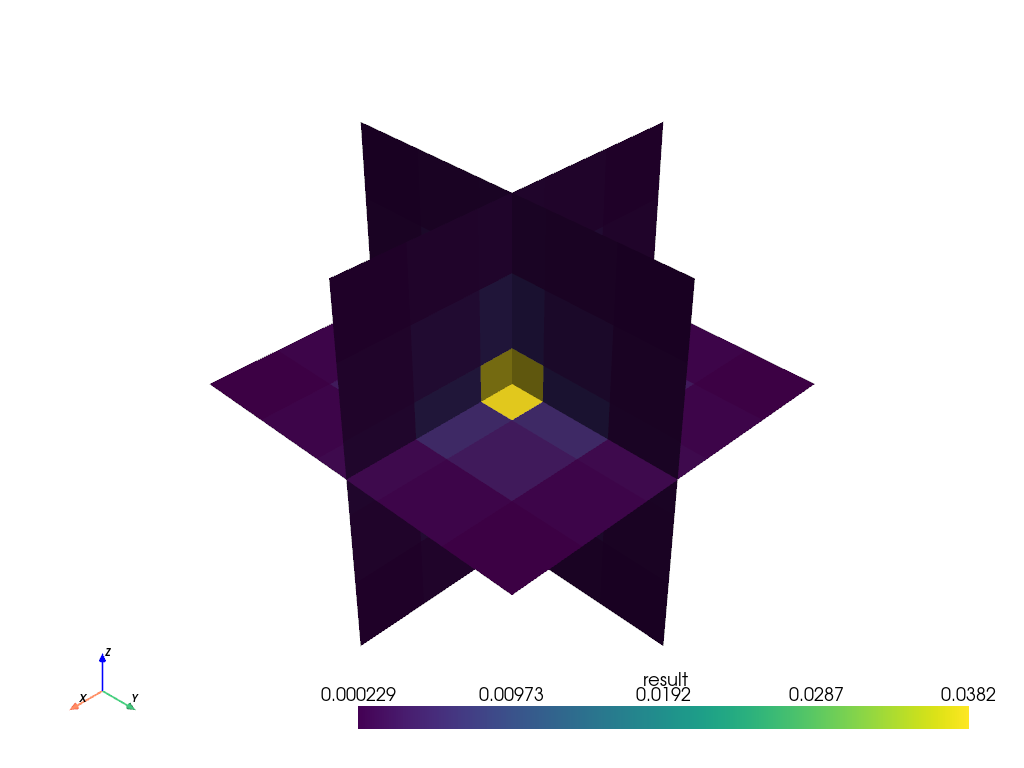

In [13]:
import pyvista as pv

pv.set_jupyter_backend("static")
p = pv.Plotter()
p.add_mesh(t14.to_pyvista().slice_orthogonal(), scalars="result", cmap="viridis")
p.add_axes()
p.show()

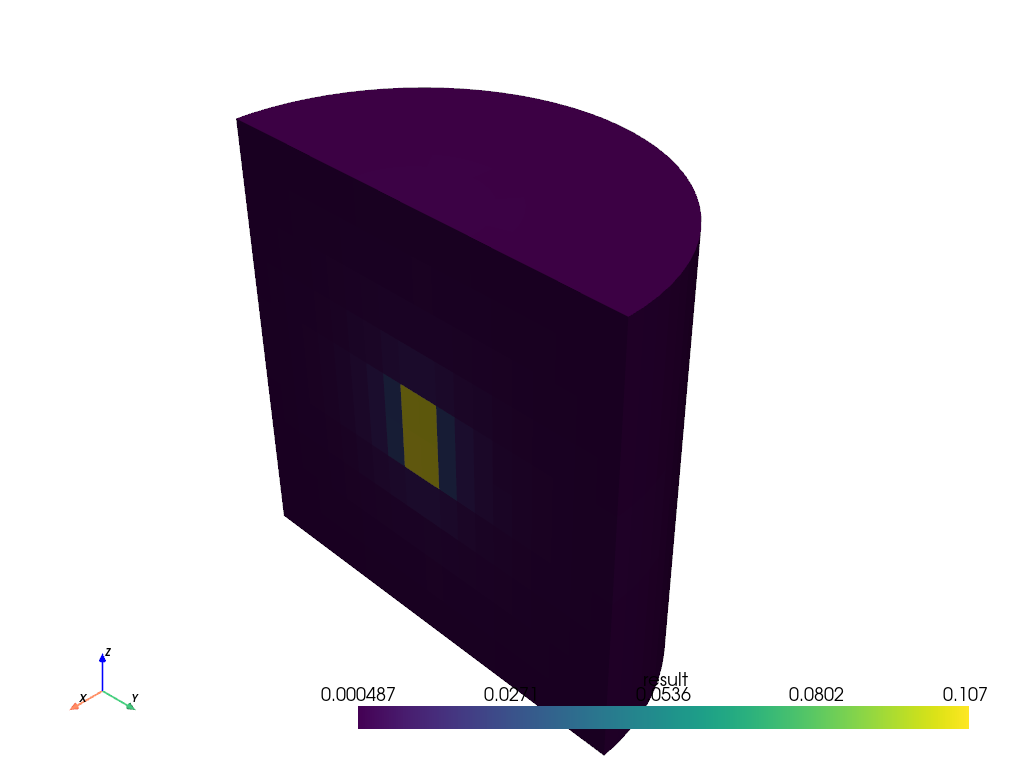

In [14]:
p = pv.Plotter()
p.add_mesh(t74.to_pyvista().clip(normal="x", origin=(0, 0, 0)), scalars="result", cmap="viridis")
p.add_axes()
p.camera_position = "iso"
p.show()

In [15]:
grid34 = t34.to_pyvista(fields=["result"])
print(grid34.array_names)

['result_e0', 'result_e1', 'result_e2', 'result_e3', 'result_e4', 'result_e5', 'result_e6', 'result_e7', 'result_e8', 'result_e9', 'result_etotal']


In [16]:
import tempfile
from pathlib import Path

out = Path(tempfile.mkdtemp())
t14.to_vtk(out / "tally14.vtr")
t74.to_vtk(out / "tally74.vts")
print(sorted(p.name for p in out.iterdir()))

['tally14.vtr', 'tally74.vts']


## MCTAL files: the F tallies

`aci_tallies.open` reads MCTAL files too (told apart by their contents).
[`../tests/fixtures/mctal/probe.mcnp`](../tests/fixtures/mctal/probe.mcnp)
fires one ray through void slabs and a lattice, so every value is known:
a slab's flux is 20 cm / 8000 cm³ = 0.0025.

In [17]:
m = aci_tallies.open("../tests/fixtures/mctal/probe.m")
m

tally,type,particles,bins,comment,warnings
1,F1,n,"f=2, c=3 incl. Total","current, cosine bins",
2,F2,n,f=2,surface flux,
4,F4,n,f=4,plain cells,
11,F1,n,"f=2, s=2","current, segments",
14,F4,n,f=4,groups and total,
24,F4,n,f=6,levels,
34,F4,n,f=4,more levels,
44,F4,n,f=6,more levels,
54,F4,n,"f=2, m=3",multipliers,
64,F4,n,"f=4, e=4 incl. Total, t=3 incl. Total",energy and time,


A tally's values have MCNP's eight axes, `f d u s m c e t`, always.
`axes` has each axis's bins (MCTAL gives upper bounds, `Axis.upper`), with
the Total bin last where MCNP printed one. `integrate` sums axes (taking
MCNP's Total bin when there is one) and `isel` selects by name.

In [18]:
t = m[64]
print(t.shape, t.axes["e"], t.axes["t"])
print("energy and time summed:", t.integrate("e", "t").result.ravel())
print("one cell, Total energy:", t.isel(f=0, e="total").result.ravel())
t.to_polars().filter(t.to_polars()["result"] > 0).head()

[4, 1, 1, 1, 1, 1, 4, 3] Axis(upper=[1.0, 10.0, 20.0], total=True) Axis(upper=[100.0, 100000.0], total=True)
energy and time summed: [0.0025 0.0025 0.0025 0.0025]
one cell, Total energy: [0.0025 0.     0.0025]


f,number,e,e_low,e_high,e_is_total,t,t_low,t_high,t_is_total,result,rel_error
u32,i64,u32,f64,f64,bool,u32,f64,f64,bool,f64,f64
0,1,2,10.0,20.0,false,0,-inf,100.0,false,0.0025,0.0
0,1,2,10.0,20.0,false,2,-inf,100000.0,true,0.0025,0.0
0,1,3,0.0,20.0,true,0,-inf,100.0,false,0.0025,0.0
0,1,3,0.0,20.0,true,2,-inf,100000.0,true,0.0025,0.0
1,2,2,10.0,20.0,false,0,-inf,100.0,false,0.0025,0.0


## Repeated structures: what each bin is

MCTAL names a bin only by its first cell (`8` for `(8 < 7[1 0 0] < 3)`).
Given the MCNP input, each bin is read from its F card and expanded the way
MCNP expands it: `str(bin)` is the name MCNP's output gives it, and
`bin.levels` its structure.

In [19]:
m = aci_tallies.open("../tests/fixtures/mctal/probe.m", input="../tests/fixtures/mctal/probe.mcnp")
t = m[24]
print(t.numbers)
for b, v in zip(t.bins, t.result.ravel()):
    print(f"{str(b):<16} {v:.5g}")
print(t.bins[3].levels)

[8, 9, 8, 8, 8, 8]
8                0.04
9                0.0047059
(8<7[0 0 0]<3)   0.01
(8<7[1 0 0]<3)   0.01
(8<7[2 0 0]<3)   0.01
(8<7[3 0 0]<3)   0.01
[[(8, None, None)], [(7, None, [1, 0, 0])], [(3, None, None)]]
